# Flip test-time augmentation for the Exp1 + Exp3 ensemble

Test-time augmentation (TTA) asks a trained model about several versions of the same photo and averages its answers. We use the simplest version: each model sees the photo and its left-right mirror, and we average the two probability vectors. A cat is still a cat in a mirror, and the models already saw mirrored photos in training (the only augmentation we trained with was a random horizontal flip), so the mirror is a fair second opinion. It cannot fix an error that both views share, but it can smooth out a model's sensitivity to one particular orientation.

Nothing is retrained. The original probabilities are already saved for Exp1 (ConvNeXt) and Exp3 (EfficientNetV2-S). We add one pass on the mirrored fold-0 images and one on the mirrored test images per model, and compare the single models and their mean with and without TTA. That is about 3 minutes of prediction for the 2,452 fold-0 images and about 35 minutes for the 18,673 test images on a Mac GPU. The mirrored predictions are saved next to each run, so a rerun reads them from disk.

By default the notebook only reads saved files. Mirrored inference needs `STAGE2_RUN_TTA_INFERENCE=1`. The submission CSV and run record are written only with `BUILD_SUBMISSION=True`. Kaggle upload is always manual.

In [1]:
from __future__ import annotations

import json
import os
import platform
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TTA_INFERENCE = True
BUILD_SUBMISSION = True  # Saves the TTA ensemble's fold-0 probabilities, run record and a binary CSV.
SUBMIT_TO_KAGGLE = False  # No submission API call exists in this notebook.

RUN_ID = 'tta_ensemble_exp1_exp3_mean_fold0'
VALIDATION_FOLD = 0
THRESHOLD = 0.25
BATCH_SIZE = 8
TTA_FOLDER_SUFFIX = '_tta'  # Mirrored predictions go to experiments/<exp>/results/<run-id>_tta/.
# Experiment folder -> completed run ID. Both runs share the fold file, label order and threshold.
MEMBERS = {
    'exp1': 'convnext_standard_fold0_seed42_20261018_full1',
    'exp3': 'efficientnetv2s_fold0_seed42',
}

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', DEVICE, '| mirrored inference:', RUN_TTA_INFERENCE, '| build submission:', BUILD_SUBMISSION)

Device: mps | mirrored inference: True | build submission: True


## Load the saved original predictions

Each completed run saved probabilities for the 2,452 fold-0 images and for the 18,673 test images, keyed by image ID. We re-score the fold-0 file and require it to match the score in the run record, and require the test file to come from the run's selected checkpoint.

In [2]:
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.ensemble import load_finetuned_network, mean_probabilities, predict_flipped_probabilities, read_probabilities, write_test_probabilities
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, read_csv, score_probabilities, split_rows, write_probabilities, write_run_record, write_submission
from stage2.run_records import file_sha256

DATA_DIR = ROOT / 'data'
_, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
val_ids = [row['image_id'] for row in validation_rows]
test_ids = [row['image_id'] for row in test_rows]
validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
fold_sha256 = file_sha256(ROOT / 'folds.csv')

records, original_val, original_test = {}, {}, {}
for name, run_id in MEMBERS.items():
    result_dir = ROOT / 'experiments' / name / 'results'
    record = json.loads((result_dir / run_id / f'{run_id}.json').read_text())
    if record['status'] != 'completed' or record['fold'] != VALIDATION_FOLD:
        raise ValueError(f'{run_id} is not a completed fold-{VALIDATION_FOLD} run.')
    if record['data']['fold_sha256'] != fold_sha256 or record['data']['label_columns'] != list(LABEL_COLUMNS) or record['metrics']['threshold'] != THRESHOLD:
        raise ValueError(f'{run_id} used a different fold file, label order or threshold.')
    original_val[name] = read_probabilities(result_dir / run_id / f'{run_id}_val.csv', val_ids)
    rescored = score_probabilities(validation_targets, original_val[name], THRESHOLD)['macro_f1']
    if not np.isclose(rescored, record['metrics']['macro_f1'], rtol=0, atol=1e-9):
        raise ValueError(f'{run_id}: re-scored macro F1 {rescored} differs from its record.')
    test_record = json.loads((result_dir / f'{run_id}_test' / f'{run_id}_test.json').read_text())
    if test_record['source_checkpoint_sha256'] != record['artifacts']['best_checkpoint_sha256']:
        raise ValueError(f'The saved test probabilities of {run_id} come from another checkpoint.')
    original_test[name] = read_probabilities(result_dir / f'{run_id}_test' / f'{run_id}_test.csv', test_ids)
    records[name] = record
    print(f'{name}: {run_id} | fold-0 macro F1 {rescored:.5f} (matches record) | test probabilities loaded')

exp1: convnext_standard_fold0_seed42_20261018_full1 | fold-0 macro F1 0.97518 (matches record) | test probabilities loaded
exp3: efficientnetv2s_fold0_seed42 | fold-0 macro F1 0.99831 (matches record) | test probabilities loaded


## Predict the mirrored images, once per member

For each member we rebuild the network from its checkpoint (the hash is checked against the run record) and predict the mirrored fold-0 and test images. The images are flipped after the usual letterboxing. Because the photos are 450×375 and fill the 384-pixel width, this is exactly the same as flipping the photo first; we checked the two agree to zero difference on 40 photos.

The mirrored probabilities are saved as `experiments/<exp>/results/<run-id>_tta/<run-id>_val_flip.csv` and `..._test_flip.csv`, each with a record of the checkpoint hash. A cached file is reused only if that hash matches. Without `STAGE2_RUN_TTA_INFERENCE=1`, a missing file is reported and skipped.

In [3]:
git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
source_files = (ROOT / 'notebooks' / '11_tta_ensemble.ipynb', ROOT / 'stage2' / 'ensemble.py', ROOT / 'stage2' / 'experiment.py')
source_sha256 = {str(path.relative_to(ROOT)): file_sha256(path) for path in source_files}


def checkpoint_path(name: str, run_id: str, record: dict) -> Path:
    shared = ROOT / 'experiments' / name / 'checkpoints' / f'{run_id}_best.ckpt'
    local = ROOT / record['artifacts'].get('best_checkpoint_local', '')
    path = next((candidate for candidate in (shared, local) if candidate.is_file()), None)
    if path is None:
        raise FileNotFoundError(f'No checkpoint for {run_id}; looked for {shared} and {local}.')
    return path


def read_flip_cache(csv_path: Path, json_path: Path, ids: list[str], record: dict):
    if not csv_path.is_file():
        return None
    if json.loads(json_path.read_text())['source_checkpoint_sha256'] != record['artifacts']['best_checkpoint_sha256']:
        raise ValueError(f'{csv_path} was made from another checkpoint.')
    return read_probabilities(csv_path, ids)


flip_val, flip_test = {}, {}
for name, run_id in MEMBERS.items():
    record = records[name]
    cache_dir = ROOT / 'experiments' / name / 'results' / f'{run_id}{TTA_FOLDER_SUFFIX}'
    val_csv, val_json = cache_dir / f'{run_id}_val_flip.csv', cache_dir / f'{run_id}_val_flip.json'
    test_csv, test_json = cache_dir / f'{run_id}_test_flip.csv', cache_dir / f'{run_id}_test_flip.json'
    flip_val[name] = read_flip_cache(val_csv, val_json, val_ids, record)
    flip_test[name] = read_flip_cache(test_csv, test_json, test_ids, record)
    missing = [split for split, found in (('fold-0', flip_val[name]), ('test', flip_test[name])) if found is None]
    if not missing:
        print(f'{name}: reused saved mirrored predictions.')
        continue
    if not RUN_TTA_INFERENCE:
        print(f'{name}: no saved mirrored predictions for {missing}; set STAGE2_RUN_TTA_INFERENCE=1 to predict them.')
        continue
    from torch.utils.data import DataLoader

    network = load_finetuned_network(record, checkpoint_path(name, run_id, record))
    for split, rows, ids, image_dir, csv_path, json_path in (
        ('fold-0', validation_rows, val_ids, 'train', val_csv, val_json), ('test', test_rows, test_ids, 'test', test_csv, test_json),
    ):
        if split not in missing:
            continue
        dataset = ImageDataset(rows, DATA_DIR / image_dir, record['data']['image_size'], record['data']['mean'], record['data']['std'])
        loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        print(f'{name}: predicting {len(rows)} mirrored {split} images on {DEVICE}...', flush=True)
        started = time.perf_counter()
        predicted_ids, probabilities = predict_flipped_probabilities(network, loader, DEVICE)
        seconds = time.perf_counter() - started
        if predicted_ids != ids:
            raise ValueError('The loader changed the image order.')
        if split == 'fold-0':
            write_probabilities(csv_path, predicted_ids, probabilities, VALIDATION_FOLD)
            flip_val[name] = probabilities
        else:
            write_test_probabilities(csv_path, predicted_ids, probabilities)
            flip_test[name] = probabilities
        write_run_record(json_path, {
            'run_id': f'{run_id}_{split.replace("-", "")}_flip', 'experiment': record['experiment'], 'status': 'flip_predicted', 'source_run_id': run_id,
            'source_checkpoint_sha256': record['artifacts']['best_checkpoint_sha256'], 'images': len(predicted_ids),
            'transform': record['data']['transform'] + '; horizontal mirror applied after letterboxing', 'git_commit': git_commit,
            'source_sha256': source_sha256, 'device': str(DEVICE), 'prediction_seconds': seconds,
            'versions': {'python': platform.python_version(), 'torch': torch.__version__},
        })
        print(f'{name}: saved {csv_path.relative_to(ROOT)} in {seconds / 60:.1f} min.')
    del network
    if DEVICE.type == 'mps':
        torch.mps.empty_cache()
    elif DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

exp1: reused saved mirrored predictions.
exp3: reused saved mirrored predictions.


## Fold 0: what does the mirror change?

For each model we compare the original predictions, the mirrored ones, and their average (the TTA prediction), then the same for the Exp1 + Exp3 mean. We keep the fixed 0.25 threshold and equal weights. On fold 0 one named-pet photo moves macro F1 by about 0.012, so differences smaller than that are not real differences, and Exp3's fold-0 score was selected on fold 0.

In [4]:
if all(flip_val[name] is not None for name in MEMBERS):
    tta_val = {name: (original_val[name] + flip_val[name]) / 2 for name in MEMBERS}
    fold0_predictions = {}
    for name in MEMBERS:
        fold0_predictions[f'{name} original'] = original_val[name]
        fold0_predictions[f'{name} mirrored'] = flip_val[name]
        fold0_predictions[f'{name} TTA'] = tta_val[name]
    fold0_predictions['mean original'] = mean_probabilities([original_val[name] for name in MEMBERS])
    fold0_predictions['mean TTA'] = mean_probabilities([tta_val[name] for name in MEMBERS])
    header = f"{'':<14} {'F1@0.25':>8} " + ' '.join(f'{label:>8}' for label in LABEL_COLUMNS) + f" {'AP':>8} {'F1@0.5':>8}"
    print(header)
    print('-' * len(header))
    fold0_scores = {}
    for label, probabilities in fold0_predictions.items():
        metrics = score_probabilities(validation_targets, probabilities, THRESHOLD)
        fold0_scores[label] = metrics
        half = score_probabilities(validation_targets, probabilities, 0.5)['macro_f1']
        per_label = ' '.join(f"{metrics['per_label_f1'][name]:>8.4f}" for name in LABEL_COLUMNS)
        print(f"{label:<14} {metrics['macro_f1']:>8.5f} {per_label} {metrics['macro_ap']:>8.5f} {half:>8.5f}")
    print()
    for name in MEMBERS:
        changed = (tta_val[name] >= THRESHOLD) != (original_val[name] >= THRESHOLD)
        print(f'{name}: TTA changes {int(changed.sum())} of {changed.size} fold-0 decisions', {label: int(changed[:, i].sum()) for i, label in enumerate(LABEL_COLUMNS) if changed[:, i].any()})
    changed = (fold0_predictions['mean TTA'] >= THRESHOLD) != (fold0_predictions['mean original'] >= THRESHOLD)
    print(f'mean: TTA changes {int(changed.sum())} fold-0 decisions', {label: int(changed[:, i].sum()) for i, label in enumerate(LABEL_COLUMNS) if changed[:, i].any()})
    print()
    print(f"{'image_id':<14} {'label':<8} {'true':>4} " + ' '.join(f'{name:>13}' for name in fold0_predictions if name.endswith(('original', 'TTA'))))
    named = [LABEL_COLUMNS.index(label) for label in ('Moris', 'Motya', 'Biatrix')]
    for row, image_id in enumerate(val_ids):
        for index in named:
            truth = bool(validation_targets[row, index])
            if any((fold0_predictions[key][row, index] >= THRESHOLD) != truth for key in fold0_predictions if key.endswith(('original', 'TTA'))):
                values = ' '.join(f'{fold0_predictions[key][row, index]:>13.3f}' for key in fold0_predictions if key.endswith(('original', 'TTA')))
                print(f'{image_id[:12]:<14} {LABEL_COLUMNS[index]:<8} {int(truth):>4} {values}')
else:
    print('Mirrored fold-0 predictions are missing; run the previous cell with STAGE2_RUN_TTA_INFERENCE=1.')

                F1@0.25      Cat      Dog    Moris    Motya  Biatrix       AP   F1@0.5
--------------------------------------------------------------------------------------
exp1 original   0.97518   0.9966   0.9970   1.0000   0.9412   0.9412  0.99443  0.97509
exp1 mirrored   0.97499   0.9966   0.9960   1.0000   0.9412   0.9412  0.99443  0.97518
exp1 TTA        0.97518   0.9966   0.9970   1.0000   0.9412   0.9412  0.99443  0.97528
exp3 original   0.99831   0.9971   0.9945   1.0000   1.0000   1.0000  0.99998  0.99832
exp3 mirrored   0.98655   0.9970   0.9945   1.0000   1.0000   0.9412  0.99719  0.98665
exp3 TTA        0.98645   0.9966   0.9945   1.0000   1.0000   0.9412  0.99998  0.98655
mean original   0.98646   0.9961   0.9950   1.0000   1.0000   0.9412  0.99999  0.99871
mean TTA        0.98636   0.9961   0.9945   1.0000   1.0000   0.9412  0.99999  0.98715

exp1: TTA changes 0 of 12260 fold-0 decisions {}
exp3: TTA changes 2 of 12260 fold-0 decisions {'Cat': 1, 'Biatrix': 1}
mean: TTA

### What the mirror looks like

The three fold-0 named-pet photos where the original and mirrored predictions of a model differ most, with each model's probability for every label in both views. If the two bars of a pair are the same height, the model did not care about the orientation. A large gap shows what TTA can smooth out.

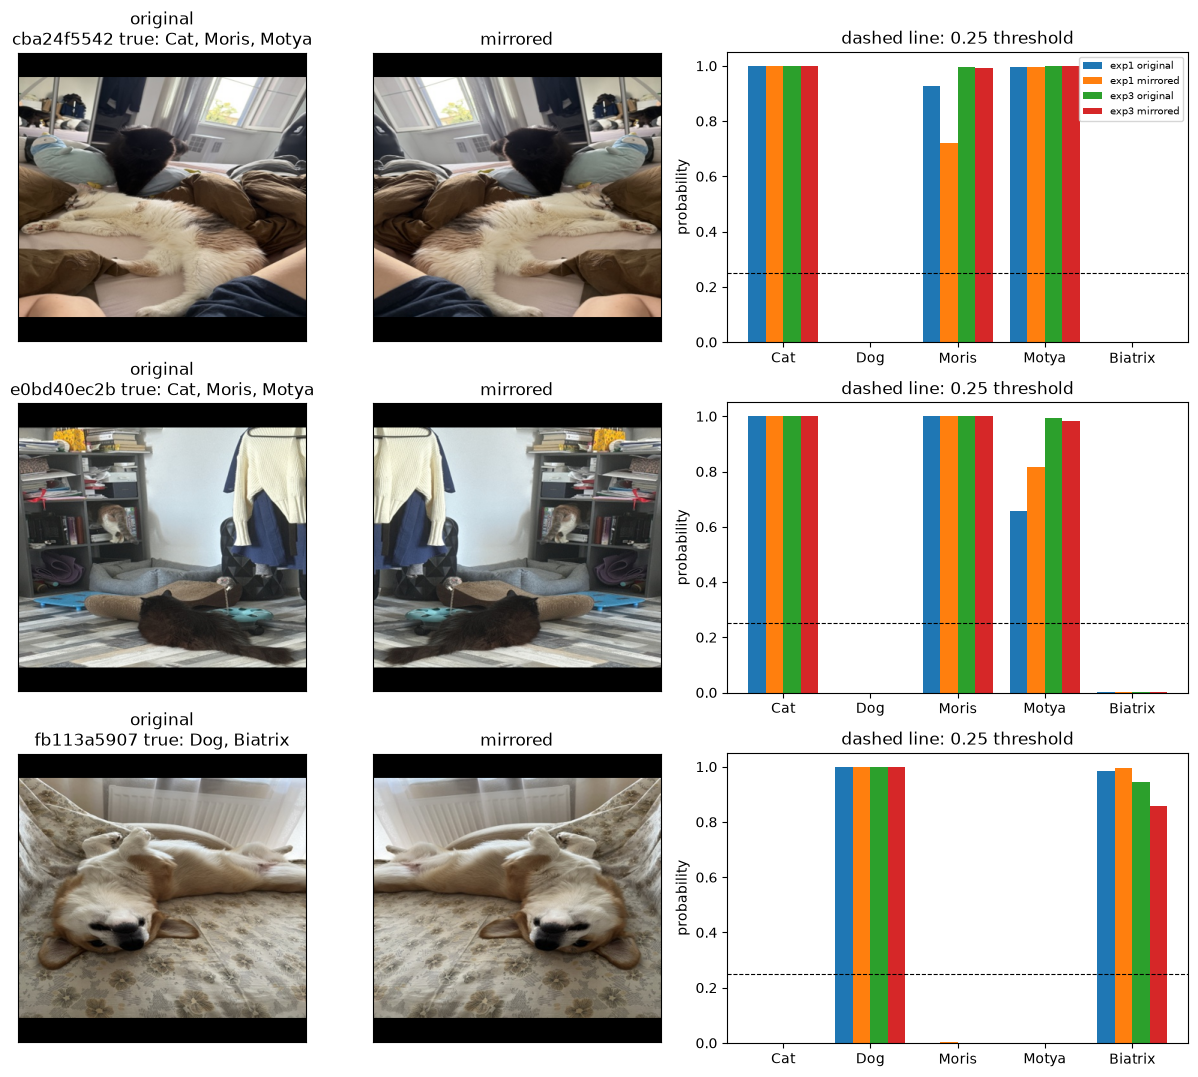

In [5]:
if all(flip_val[name] is not None for name in MEMBERS):
    import matplotlib.pyplot as plt

    named = [LABEL_COLUMNS.index(label) for label in ('Moris', 'Motya', 'Biatrix')]
    gap = np.max([np.abs(original_val[name][:, named] - flip_val[name][:, named]) * validation_targets[:, named] for name in MEMBERS], axis=(0, 2))
    chosen = [int(i) for i in np.argsort(-gap)[:3]]
    plain = ImageDataset(validation_rows, DATA_DIR / 'train', 384, (0, 0, 0), (1, 1, 1))  # No normalization: images stay displayable.
    figure, axes = plt.subplots(len(chosen), 3, figsize=(12, 3.6 * len(chosen)), gridspec_kw={'width_ratios': [1, 1, 1.6]})
    positions = np.arange(len(LABEL_COLUMNS))
    for row, index in enumerate(chosen):
        _, image, _ = plain[index]
        image = image.permute(1, 2, 0).numpy()
        truth = [label for label, value in zip(LABEL_COLUMNS, validation_targets[index]) if value]
        axes[row, 0].imshow(image)
        axes[row, 0].set(title=f'original\n{val_ids[index][:10]} true: {", ".join(truth)}', xticks=[], yticks=[])
        axes[row, 1].imshow(image[:, ::-1])
        axes[row, 1].set(title='mirrored', xticks=[], yticks=[])
        for offset, (name, view, probabilities) in enumerate([(n, v, p) for n in MEMBERS for v, p in (('original', original_val[n]), ('mirrored', flip_val[n]))]):
            axes[row, 2].bar(positions + (offset - 1.5) * 0.2, probabilities[index], width=0.2, label=f'{name} {view}')
        axes[row, 2].axhline(THRESHOLD, color='black', linestyle='--', linewidth=0.8)
        axes[row, 2].set(xticks=positions, xticklabels=LABEL_COLUMNS, ylim=(0, 1.05), ylabel='probability', title='dashed line: 0.25 threshold')
    axes[0, 2].legend(fontsize=7)
    figure.tight_layout()
    plt.show()
else:
    print('Mirrored fold-0 predictions are missing.')

## Test set: how many decisions does TTA change?

The table shows how many test cells each model flips when its mirrored prediction is averaged in, and the positives per label before and after. A handful of changes cannot move the leaderboard; dozens can, in either direction, and only a manual upload shows which. The mean of the two TTA predictions is the average of all four passes.

In [6]:
if all(flip_test[name] is not None for name in MEMBERS):
    tta_test = {name: (original_test[name] + flip_test[name]) / 2 for name in MEMBERS}
    original_mean = mean_probabilities([original_test[name] for name in MEMBERS])
    tta_mean = mean_probabilities([tta_test[name] for name in MEMBERS])
    print(f"{'labels':<8} " + ' '.join(f'{name:>10}' for name in ('exp1', 'exp1 TTA', 'exp3', 'exp3 TTA', 'mean', 'mean TTA')))
    for index, label in enumerate(LABEL_COLUMNS):
        counts = [int((matrix[:, index] >= THRESHOLD).sum()) for matrix in (original_test['exp1'], tta_test['exp1'], original_test['exp3'], tta_test['exp3'], original_mean, tta_mean)]
        print(f'{label:<8} ' + ' '.join(f'{count:>10}' for count in counts))
    print()
    for label, before, after in (('exp1', original_test['exp1'], tta_test['exp1']), ('exp3', original_test['exp3'], tta_test['exp3']), ('mean', original_mean, tta_mean)):
        changed = (after >= THRESHOLD) != (before >= THRESHOLD)
        print(f'{label}: TTA changes {int(changed.sum())} of {changed.size} test cells', {name: int(changed[:, i].sum()) for i, name in enumerate(LABEL_COLUMNS)})
    changed = (tta_mean >= THRESHOLD) != (original_mean >= THRESHOLD)
    print(f'The mean TTA ensemble differs from the submitted mean (public 0.97761) in {int(changed.sum())} cells.')
else:
    tta_mean = None
    print('Mirrored test predictions are missing; no TTA ensemble yet.')

if BUILD_SUBMISSION:
    if tta_mean is None:
        raise ValueError('Predict the mirrored test images for every member before building a submission.')
    result_dir = ROOT / 'experiments' / 'exp4' / 'results' / RUN_ID
    submission_path = ROOT / 'submissions' / f"exp4_{RUN_ID.removesuffix('_fold0')}_{round(THRESHOLD * 100):03d}.csv"
    for path in (submission_path, result_dir / f'{RUN_ID}.json', result_dir / f'{RUN_ID}_val.csv'):
        if path.exists():
            raise FileExistsError(f'Refusing to overwrite {path}')
    write_submission(submission_path, form_submission(DATA_DIR / 'sample_submission.csv', test_ids, tta_mean, THRESHOLD))
    write_probabilities(result_dir / f'{RUN_ID}_val.csv', val_ids, fold0_predictions['mean TTA'], VALIDATION_FOLD)
    write_run_record(result_dir / f'{RUN_ID}.json', {
        'run_id': RUN_ID, 'experiment': '04_ensemble', 'status': 'completed', 'fold': VALIDATION_FOLD,
        'method': 'equal-weight mean of each member\'s original and mirrored probabilities (flip TTA), then fixed threshold',
        'members': [{'experiment': records[name]['experiment'], 'run_id': run_id, 'checkpoint_sha256': records[name]['artifacts']['best_checkpoint_sha256'],
                     'fold0_macro_f1_original': fold0_scores[f'{name} original']['macro_f1'], 'fold0_macro_f1_tta': fold0_scores[f'{name} TTA']['macro_f1']} for name, run_id in MEMBERS.items()],
        'data': {'fold_file': 'folds.csv', 'fold_sha256': fold_sha256, 'label_columns': list(LABEL_COLUMNS)},
        'metrics': {**fold0_scores['mean TTA'], 'macro_f1_at_0_5': score_probabilities(validation_targets, fold0_predictions['mean TTA'], 0.5)['macro_f1']},
        'artifacts': {'validation_probabilities_csv': str((result_dir / f'{RUN_ID}_val.csv').relative_to(ROOT)), 'submission_csv': str(submission_path.relative_to(ROOT))},
        'git_commit': git_commit, 'source_sha256': source_sha256, 'public_leaderboard_score': None, 'error': None,
    })
    print('CSV ready for manual review:', submission_path.relative_to(ROOT))
    print('Run record:', (result_dir / f'{RUN_ID}.json').relative_to(ROOT))
else:
    print('No submission CSV built or uploaded.')

labels         exp1   exp1 TTA       exp3   exp3 TTA       mean   mean TTA
Cat            7781       7781       7809       7820       7815       7816
Dog            7675       7677       7659       7668       7699       7701
Moris           162        163        161        163        171        172
Motya           129        127        129        131        131        130
Biatrix         187        188        181        182        187        184

exp1: TTA changes 22 of 93365 test cells {'Cat': 4, 'Dog': 8, 'Moris': 5, 'Motya': 4, 'Biatrix': 1}
exp3: TTA changes 45 of 93365 test cells {'Cat': 19, 'Dog': 15, 'Moris': 2, 'Motya': 4, 'Biatrix': 5}
mean: TTA changes 32 of 93365 test cells {'Cat': 13, 'Dog': 14, 'Moris': 1, 'Motya': 1, 'Biatrix': 3}
The mean TTA ensemble differs from the submitted mean (public 0.97761) in 32 cells.
CSV ready for manual review: submissions/exp4_tta_ensemble_exp1_exp3_mean_025.csv
Run record: experiments/exp4/results/tta_ensemble_exp1_exp3_mean_fold0/tta_ense

## Results and conclusions

| Model | Fold-0 macro F1 at 0.25 | Public leaderboard |
|---|---:|---:|
| Exp1: ConvNeXt-base | 0.97518 | 0.97003 |
| Exp3: EfficientNetV2-S | 0.99831 | 0.97015 |
| Mean of Exp1 and Exp3, no TTA | 0.98646 | **0.97761** |
| Mean of Exp1 and Exp3 **with flip TTA** (this notebook) | 0.98636 | 0.97420 |

Public scores come from the Kaggle submission list, entered by hand. Fold 0 is a screening result, not five-fold CV.

**1. Flip TTA made the leaderboard score worse.** 0.97420 is 0.0034 below the same ensemble without TTA (0.97761). It is still 0.004 above either single model, so the ensembling gain survives, but the mirror took part of it away. We do not adopt TTA, and the Exp1 + Exp3 mean without TTA stays our best submission.

**2. A very small change caused the drop.** TTA changed only 32 of 93,365 test cells (0.03%): 27 Cat or Dog cells and 5 named-pet cells (Moris 1, Motya 1, Biatrix 3). With macro F1 every label counts one fifth, and a named-pet cell is worth roughly 50 times a Cat or Dog cell (about 0.0007 against 0.00001) because the pets have only 130–190 positives each. Five named-pet cells at about 0.0007 add up to about 0.0035, which is almost exactly the drop. The result is therefore consistent with nearly all five named-pet changes being wrong. Test labels are hidden, so we cannot confirm it. The predicted Biatrix count fell from 187 to 184, so some of those changes removed real Biatrix photos.

**3. Our own estimate was too optimistic.** Before submitting we expected a change within about ±0.001 and a worst case of ±0.003. The actual change fell just outside that worst case, because we did not weigh how few rare-label photos decide the score. The lesson is that a change of only a handful of named-pet cells is enough to move the leaderboard by several thousandths in either direction, so such changes are not safe to submit without a labelled check.

**4. Fold 0 could not see this.** On fold 0 TTA changed no named-pet decision for the ensemble, and one Dog decision in total, so fold 0 predicted no effect. The 5 test cells that decided the result are rare cases that 8–10 validation photos per pet do not contain.

**5. Why the mirror may not help here (not tested).** The mirror is not a neutral view for these photos. Both models were trained with random flips, but only half the time, and the photos are home scenes in which the pets are often small and the surroundings carry cues, so the mirrored view can be a slightly worse view than the original. On fold 0 the mirrored predictions were never better than the originals (Exp1 0.97499 against 0.97518, Exp3 0.98655 against 0.99831; the original Exp3 view also chose the checkpoint, which favours it). Averaging in a view that is not better pulls probabilities that sit near the 0.25 threshold across it, and the threshold itself was fixed for the original-view probabilities. We did not test any of these explanations.